# Setup Instructions

1. Upload this notebook and `earlycommit.zip` to Google Colab.
2. Unzip `earlycommit.zip` so you have an `Earlycommit` folder.
3. Move this notebook into the `Earlycommit` folder (not inside any subfolder).
4. Connect a GPU runtime.
5. Run the two required setup cells below before using any section.

---

## Notebook Sections

You can jump to any section in any order:

- **EarlyCommit: Fine-tuning Laya**  
  Use this to fine-tune the model.

- **System Evaluation**  
  Use this to evaluate the model’s performance.

- **Demo**  
  Use this to run interactive demos with the model.

---

## Using Checkpoints

- The `checkpoints` subfolder inside `Earlycommit` already contains trained checkpoints.
- If you fine-tune the model, save your new checkpoints in this same `checkpoints` folder.
- The Evaluation and Demo sections will use whatever checkpoints are in that folder.

# Setup cell 1

In [ ]:
# --- Setup: works in Google Colab and in a local Jupyter started from the EarlyCommit folder ---
import os, sys
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not os.path.exists('/content/EarlyCommit/src'):
        assert os.path.exists('/content/EarlyCommit.zip'), 'Upload EarlyCommit.zip to /content first (file panel on the left).'
        !unzip -q -o /content/EarlyCommit.zip -d /content
    %cd /content/EarlyCommit
ROOT = os.getcwd()
assert os.path.exists(os.path.join(ROOT, 'src', 'earlycommit')), 'Run this notebook from the EarlyCommit folder.'
os.environ['PYTHONPATH'] = os.path.join(ROOT, 'src')   # lets `python -m earlycommit.<module>` find the code in src/
os.environ['USE_TF'] = '0'                             # stops transformers from loading TensorFlow (can hang)
sys.path.insert(0, os.path.join(ROOT, 'src'))
print('project root:', ROOT)

# Setup cell 2

In [ ]:
# Install Laya only. Do NOT upgrade numpy/scipy here: that breaks an already running Colab session.
!pip install -q "laya>=0.3.7"
!python -c "import laya, torch; print('laya', laya.__version__, '| torch', torch.__version__, '| CUDA', torch.cuda.is_available())"

# EarlyCommit: fine-tuning Laya

Trains the two checkpoints used in the paper with Laya's own training recipe (RLCD: policy gradient on a proper scoring rule plus soft cross-entropy).

| Checkpoint | Command flag | Training data |
|---|---|---|
| `checkpoints/laya-earlycommit` | none | 4,000 template instructions, 30,972 prefixes |
| `checkpoints/laya-earlycommit-aug` | `--augment 0.5` | same, half rewritten with train-pool words, 33,007 prefixes |

**Colab:** Runtime → Change runtime type → **A100 GPU** (a T4 also works but is much slower; reduce `--micro-batch` to 16 and raise `--grad-accum` to 4 if memory runs out). Upload `EarlyCommit.zip` to `/content`, then run the cells from the top.

GPU training is not bit-for-bit deterministic, so retrained checkpoints can differ slightly from the paper's.

In [ ]:
import torch
assert torch.cuda.is_available(), 'No GPU: Runtime -> Change runtime type -> GPU'
print(torch.cuda.get_device_name(0), '| bf16:', torch.cuda.is_bf16_supported())

## 1. Laya without augmentation
Prints the validation loss and accuracy on determined prefixes before training (the paper reports 44% for the base model) and after each epoch, then the internal temperature.

In [ ]:
!python -m src.earlycommit.train --out checkpoints/laya-earlycommit --micro-batch 32 --grad-accum 2 | tee logs_train_noaug.txt

## 2. Laya with augmentation

In [ ]:
!python -m src.earlycommit.train --out checkpoints/laya-earlycommit-aug --augment 0.5 --micro-batch 32 --grad-accum 2 | tee logs_train_aug.txt

## 3. Save the checkpoints
Colab deletes files when the session ends. Zip the checkpoints and keep them in Google Drive. `evaluation.ipynb` and `demo.ipynb` accept these zips.

In [ ]:
!ls checkpoints/laya-earlycommit checkpoints/laya-earlycommit-aug
!cd checkpoints && zip -qr laya-earlycommit.zip laya-earlycommit && zip -qr laya-earlycommit-aug.zip laya-earlycommit-aug && ls -lh *.zip

In [ ]:
# OPTIONAL: copy to Google Drive
# from google.colab import drive; drive.mount('/content/drive')
# !cp checkpoints/laya-earlycommit.zip checkpoints/laya-earlycommit-aug.zip /content/drive/MyDrive/

`evaluation.ipynb` (in the same session the checkpoints are already in place, skip its part C).

# EarlyCommit: evaluation

This notebook reproduces every number, table and figure in the paper.

| Part | Needs | Time |
|---|---|---|
| A. Regenerate tables and figures from the included result files | CPU | < 1 min |
| B. Smoke test of the whole pipeline with a mock judge | CPU | ~1 min |
| C. Unpack the fine-tuned checkpoints | CPU | ~1 min |
| D. Latency benchmark | GPU | ~2 min |
| E. Full evaluation (the three runs behind the paper) | GPU | ~20–30 min on A100, longer on T4 |
| F. Regenerate tables and figures from your new runs and compare | CPU | < 1 min |

**Colab:** Runtime → Change runtime type → GPU (A100 or T4). Upload `EarlyCommit.zip` to `/content` with the file panel, then run the cells from the top.

## A. Reproduce the paper from the included results (no GPU)
`results/` holds the three result files used in the paper. This regenerates Table 1, Table 2, Figures 3 and 4 and the bar chart in Figure 2, prints every headline number and checks it against the paper.

In [ ]:
!python -m src.earlycommit.paper --results results --out paper_outputs

In [ ]:
from IPython.display import Image, display
display(Image('paper_outputs/fig_tradeoff.png', width=900))
display(Image('paper_outputs/fig_reliability.png', width=500))

## B. Smoke test with a mock judge (no GPU, no checkpoint)
Runs data generation, calibration, the commit rule and the robustness conditions end to end. The mock judge is the oracle plus noise, so its numbers are **not** paper numbers.

In [ ]:
!python -m src.earlycommit.run ood --judge mock --n-val 60 --n-test 100 --out mock_smoke_test.json | tail -8

## C. Fine-tuned checkpoints
The evaluation needs the two fine-tuned checkpoints (Laya without augmentation and Laya with augmentation). See README section *Checkpoints* for where to get them, or train them with `training.ipynb`. If you trained them with `training.ipynb` in this session they are already in `checkpoints/` and you can skip this part.

In [ ]:
# OPTIONAL: if the checkpoint zips are in Google Drive, mount it and copy them into checkpoints/.
# from google.colab import drive; drive.mount('/content/drive')
# !cp /content/drive/MyDrive/laya-earlycommit.zip /content/drive/MyDrive/laya-earlycommit-aug.zip checkpoints/

In [ ]:
# Unpack the two fine-tuned checkpoints into checkpoints/ (skipped if already there, e.g. after training.ipynb).
# Put laya-earlycommit.zip and laya-earlycommit-aug.zip in EarlyCommit/checkpoints/ first,
# or change the two paths below (e.g. to /content/drive/MyDrive/...).
NOAUG_ZIP = 'checkpoints/laya-earlycommit.zip'
AUG_ZIP   = 'checkpoints/laya-earlycommit-aug.zip'
if not os.path.exists('checkpoints/laya-earlycommit/rl_agent_config.json'):
    !python -m earlycommit.checkpoints --zip {NOAUG_ZIP} --name laya-earlycommit
if not os.path.exists('checkpoints/laya-earlycommit-aug/rl_agent_config.json'):
    !python -m earlycommit.checkpoints --zip {AUG_ZIP} --name laya-earlycommit-aug

In [ ]:
!ls checkpoints/laya-earlycommit checkpoints/laya-earlycommit-aug

## D. Latency benchmark (GPU)


In [ ]:
!python -m src.earlycommit.bench --device cuda --repo checkpoints/laya-earlycommit --n 100 | tee bench_output.txt



## E. Full evaluation (GPU)
The three runs behind the paper, started in parallel. Each fits the temperature on 500 validation instructions and evaluates 1,500 test instructions under six conditions and seven thresholds.

| Run | Model | Temperature fitted on | Paper result file |
|---|---|---|---|
| 1 | Laya | calibration pool | `results/final_noaug.json` |
| 2 | Laya + aug. | calibration pool | `results/final_aug.json` |
| 3 | Laya + aug. | training pool (Table 2 ablation) | `results/final_aug_trainpool.json` |

The cell ends when all three are done. Logs go to `logs/`.

In [ ]:
import os
TAUS = '0.5,0.6,0.7,0.8,0.85,0.9,0.95'
COMMON = f'--judge laya --device cuda --n-val 500 --n-test 1500 --taus {TAUS}'
os.makedirs('logs', exist_ok=True)
!python -m src.earlycommit.run ood {COMMON} --repo checkpoints/laya-earlycommit --val-pool calib --out final_noaug.json > logs/final_noaug.txt 2>&1 & python -m earlycommit.run ood {COMMON} --repo checkpoints/laya-earlycommit-aug --val-pool calib --out final_aug.json > logs/final_aug.txt 2>&1 & python -m earlycommit.run ood {COMMON} --repo checkpoints/laya-earlycommit-aug --val-pool train --out final_aug_trainpool.json > logs/final_aug_trainpool.txt 2>&1 & wait
!grep -H -E "temperatures|saved" logs/*.txt

If a run did not print `saved`, look at its log: `!tail -30 logs/final_aug.txt`.

## F. Tables and figures from your runs
New results are in `outputs/`. The checks compare them with the paper. Small differences can come from a different GPU or from retrained checkpoints.

In [ ]:
!python -m src.earlycommit.paper --results outputs --out paper_outputs_new

In [ ]:
!zip -qr my_results.zip outputs paper_outputs_new logs bench_output.txt
if IN_COLAB:
    from google.colab import files; files.download('my_results.zip')

# EarlyCommit: demo

Renders the videos behind Figure 1: two kinematic arms side by side, one committing word by word (EarlyCommit) and one waiting for the whole sentence (baseline), with the probability of every object after each word.

* Parts 1–2 run **without GPU or checkpoint** using a mock judge.
* Parts 3–5 use the fine-tuned judge (Laya + aug.) with the paper's temperature **T = 5.29** and **τ = 0.9**, and real speech (text-to-speech or your own recording, streamed through Whisper).

The demo is a visualisation of the judge's decisions, not a physics simulation.

In [2]:
from IPython.display import Image, Video, display
def show(path, width=900):
    display(Video(path, embed=True, width=width))

## 1. Look at a scene
Every `--seed` gives a different table. The same seed always gives the same scene.

scene --seed 3:
  obj_0: white cup (left front)
  obj_1: red cup (middle front)
  obj_2: white bottle (middle back)
  obj_3: red cup (left back)
  obj_4: black bottle (right back)
saved outputs/scene_3.png


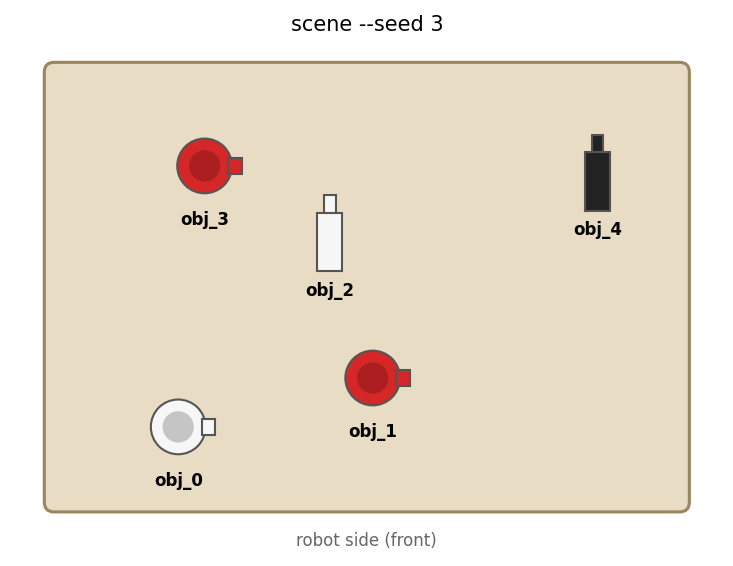

In [6]:
SEED = 3
!python -m src.earlycommit.demo --show-scene --seed {SEED} --out outputs/scene.mp4
display(Image(f'outputs/scene_{SEED}.png', width=500))

## 2. Quick demo with the mock judge (no GPU)

In [7]:
!python -m src.earlycommit.demo --judge mock --temperature 1.3 --tau 0.9 --seed {SEED} --target obj_1 --out outputs/mock_obj_1.mp4
show('outputs/mock_obj_1.mp4')

sentence : can you get the red cup in the middle for me
scene    : obj_0=white cup (left front), obj_1=red cup (middle front), obj_2=white bottle (middle back), obj_3=red cup (left back), obj_4=black bottle (right back)
judge    : median 0.0 ms per word
   1 can        top=obj_0 0.28
   2 you        top=obj_4 0.23
   3 get        top=obj_3 0.29
   4 the        top=obj_1 0.38
   5 red        top=obj_1 0.66
   6 cup        top=obj_3 0.73
   7 in         top=obj_3 0.61
   8 the        top=obj_3 0.56
   9 middle     top=obj_1 0.99   <- COMMIT
  10 for        top=obj_1 0.98
  11 me         top=obj_1 0.98
truth    : obj_1 | committed: obj_1 | baseline: obj_1
EarlyCommit finished its reach 0.60 s before the baseline
saved outputs/mock_obj_1.mp4 and outputs/mock_obj_1.png


## 3. The fine-tuned judge
Skip this cell if `checkpoints/laya-earlycommit-aug` already exists (for example after `training.ipynb`). Otherwise put `laya-earlycommit-aug.zip` in `checkpoints/` (see README, *Checkpoints*).

In [13]:
# from google.colab import drive; drive.mount('/content/drive')      # if the zip is in Drive
# !cp /content/drive/MyDrive/laya-earlycommit-aug.zip checkpoints/
import os
if not os.path.exists('checkpoints/laya-earlycommit-aug'):
    !python -m src.earlycommit.checkpoints --zip checkpoints/laya-earlycommit-aug.zip --name laya-earlycommit-aug
R = 'checkpoints/laya-earlycommit-aug'
T, TAU = 5.29, 0.9
DEV = 'cuda'   # use 'cpu' if you have no GPU (slower but works)

In [14]:
# One generated instruction per cup in scene 3, each rendered as its own video.
for t in ['obj_0', 'obj_1', 'obj_3']:
    !python -m src.earlycommit.demo --judge laya --repo {R} --device {DEV} --temperature {T} --tau {TAU} --seed {SEED} --target {t} --out outputs/grab_{t}.mp4 | grep -E "sentence|COMMIT|truth|finished"
show('outputs/grab_obj_1.mp4')

sentence : can you get the white cup on the left for me
   6 cup        top=obj_0 0.98   <- COMMIT
truth    : obj_0 | committed: obj_0 | baseline: obj_0
EarlyCommit finished its reach 1.50 s before the baseline
sentence : can you get the red cup in the middle for me
   9 middle     top=obj_1 0.98   <- COMMIT
truth    : obj_1 | committed: obj_1 | baseline: obj_1
EarlyCommit finished its reach 0.60 s before the baseline
sentence : can you get the red cup on the left for me
   9 left       top=obj_3 0.98   <- COMMIT
truth    : obj_3 | committed: obj_3 | baseline: obj_3
EarlyCommit finished its reach 0.60 s before the baseline


## 4. Real speech: text-to-speech streamed through Whisper
The printed log shows what Whisper heard after every 0.3 s and which words it released. The Figure 1 clip is `speech_fig1.mp4`.

In [15]:
!python -m src.earlycommit.demo --judge laya --repo {R} --device {DEV} --asr-device {DEV} --temperature {T} --tau {TAU} --seed {SEED} --speak "grab the red cup in the middle please" --out outputs/speech_fig1.mp4
show('outputs/speech_fig1.mp4')

audio    : outputs/speech_fig1.wav (2.89 s)
streaming ASR (whisper, hop 0.3s):
  t=1.10s (+301 ms)  heard: 'grab the ra'                                           -> released: grab
  t=1.40s (+301 ms)  heard: 'grab the red cup'                                      -> released: the
  t=1.70s (+322 ms)  heard: 'grab the red cup'                                      -> released: red cup
  t=2.30s (+338 ms)  heard: 'grab the red cup in the middle'                        -> released: in the middle
  t=2.89s (+372 ms)  heard: 'grab the red cup in the middle please'                 -> released: please
ASR decode: median 336 ms per re-decode
sentence : grab the red cup in the middle please
scene    : obj_0=white cup (left front), obj_1=red cup (middle front), obj_2=white bottle (middle back), obj_3=red cup (left back), obj_4=black bottle (right back)
judge    : median 149.6 ms per word
   1 grab       top=obj_1 0.20
   2 the        top=obj_1 0.20
   3 red        top=obj_1 0.50
   4 cup        

In [16]:
# An ambiguous request: both robots should ask which cup is meant.
!python -m src.earlycommit.demo --judge laya --repo {R} --device {DEV} --asr-device {DEV} --temperature {T} --tau {TAU} --seed {SEED} --speak "grab the cup please" --out outputs/speech_ambiguous.mp4 | grep -E "truth|saved"
show('outputs/speech_ambiguous.mp4')

truth    : None | committed: None | baseline: None
saved outputs/speech_ambiguous.mp4 and outputs/speech_ambiguous.png


## 5. Your own voice
Record a sentence about the scene in part 1 (for example "can you get the white cup on the left"), upload the file (wav, mp3 or m4a), then run the next cell.

In [ ]:
MY_AUDIO = 'my_voice.m4a'          # path of your uploaded recording
INTENDED = 'can you get the white cup on the left'   # what you said (used only to print the truth)
if IN_COLAB and not os.path.exists(MY_AUDIO):
    from google.colab import files; up = files.upload(); MY_AUDIO = list(up)[0]
!python -m src.earlycommit.demo --judge laya --repo {R} --device {DEV} --asr-device {DEV} --temperature {T} --tau {TAU} --seed {SEED} --audio "{MY_AUDIO}" --intended "{INTENDED}" --out outputs/speech_me.mp4
show('outputs/speech_me.mp4')

In [ ]:
!zip -qj demos.zip outputs/*.mp4 outputs/*.png
if IN_COLAB:
    from google.colab import files; files.download('demos.zip')